In [1]:
import os, sys, json, time, hashlib, subprocess, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import lightgbm as lgb
import pyarrow, sklearn, mlflow
from dotenv import load_dotenv

warnings.filterwarnings("ignore")

# ---- config ----
EXPERIMENT = "final_model_test"
DATA_PATH = "../data/processed/rain_v2_3month_dataset_02.parquet"
FEATURE_PATH = "../data/processed/rain_v2_3month_feature_list_02.json"
PROCESSED = Path(DATA_PATH).parent
TRAIN_START, TRAIN_END = 1901, 2002
VAL_START, VAL_END = 2003, 2013
TEST_START, TEST_END = 2014, 2025   # test is NOT touched in this notebook
OUTLIER_THRESHOLD = 6
SD_FLOOR = 5
RANDOM_STATE = 42
BUFFER_FROM_MONTH = 10              # origin Oct-Dec before a val block are dropped from train

FOLDS = {
    "A": dict(train_start=1901, train_end=1950, val_start=1951, val_end=1975),
    "B": dict(train_start=1901, train_end=1975, val_start=1976, val_end=2002),
}

DEFAULT_PARAMS = dict(
    n_estimators=300, learning_rate=0.05, num_leaves=31, max_depth=-1,
    min_child_samples=100, subsample=0.8, colsample_bytree=0.8,
    reg_lambda=1.0, random_state=RANDOM_STATE,
)

def file_md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

GIT_COMMIT = subprocess.check_output(["git", "rev-parse", "--short", "HEAD"], text=True).strip()
DATASET_MD5 = file_md5(DATA_PATH)

for name, ver in [("python", sys.version.split()[0]), ("lightgbm", lgb.__version__),
                  ("numpy", np.__version__), ("pandas", pd.__version__),
                  ("pyarrow", pyarrow.__version__), ("scikit-learn", sklearn.__version__),
                  ("mlflow", mlflow.__version__)]:
    print(f"{name:13s}{ver}")
print("git commit  ", GIT_COMMIT)
print("dataset md5 ", DATASET_MD5)

# ---- MLflow (token is read from .env, never printed) ----
load_dotenv("../../.env")
os.environ["MLFLOW_TRACKING_USERNAME"] = "Sharanya-0224"
os.environ["MLFLOW_TRACKING_PASSWORD"] = os.environ["DAGSHUB_USER_TOKEN"]
mlflow.set_tracking_uri("https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow")
mlflow.set_system_metrics_sampling_interval(1)
mlflow.set_experiment(EXPERIMENT)
print("MLflow experiment:", EXPERIMENT)

/home/sharanya/Climate-Change-Awareness-Dashboard/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


python       3.12.3
lightgbm     4.7.0
numpy        2.0.2
pandas       2.3.3
pyarrow      25.0.1
scikit-learn 1.9.1
mlflow       3.17.1
git commit   28b6139
dataset md5  8ea8f7473d958fb34548ab9e66dbff97


2026/11/12 14:08:57 INFO mlflow.tracking.fluent: Experiment with name 'final_model_test' does not exist. Creating a new experiment.


MLflow experiment: final_model_test


In [10]:
def metrics(y_true, y_pred, y_true_mm, y_pred_mm):
    mse = np.mean((y_true - y_pred) ** 2)
    mse_clim = np.mean(y_true ** 2)

    return {
        "mse": mse,
        "mse_skill": 1 - mse / mse_clim if mse_clim > 0 else np.nan,
        "rmse_z": np.sqrt(mse),
        "mae_z": np.mean(np.abs(y_true - y_pred)),
        "bias_z": np.mean(y_pred - y_true),
        "acc": np.corrcoef(y_true, y_pred)[0, 1]
            if np.std(y_true) > 0 and np.std(y_pred) > 0 else np.nan,
        "r2": 1 - np.sum((y_true - y_pred) ** 2) /
            np.sum((y_true - np.mean(y_true)) ** 2)
            if np.sum((y_true - np.mean(y_true)) ** 2) > 0 else np.nan,
        "rmse_mm": np.sqrt(np.mean((y_true_mm - y_pred_mm) ** 2)),
        "mae_mm": np.mean(np.abs(y_true_mm - y_pred_mm)),
        "bias_mm": np.mean(y_pred_mm - y_true_mm)
    }


def categorical_metrics(y_true, y_pred, lower, upper):
    def classify(values):
        return np.where(
            values < lower, 0,
            np.where(values > upper, 2, 1)
        )

    observed = classify(y_true)
    predicted = classify(y_pred)

    confusion = pd.crosstab(
        pd.Series(observed),
        pd.Series(predicted)
    ).reindex(index=[0, 1, 2], columns=[0, 1, 2], fill_value=0).values

    n = confusion.sum()
    accuracy = np.trace(confusion) / n

    expected = np.sum(
        confusion.sum(axis=0) * confusion.sum(axis=1)
    ) / n**2

    hss = (
        (accuracy - expected) / (1 - expected)
        if expected < 1 else np.nan
    )

    return {
        "tercile_accuracy": accuracy,
        "hss": hss
    }

In [ ]:
train_df = df.loc[df["split"] == "train"] #used here only to establish the tercile thresholds

tercile_thresholds = (
    train_df.groupby(["key", "month"])["target_z"]
    .quantile([1/3, 2/3])
    .unstack()
    .reset_index()
)

tercile_thresholds.columns = [
    "key", "month", "lower_threshold", "upper_threshold"
]

print("Threshold groups:", len(tercile_thresholds))
display(tercile_thresholds.head())

Threshold groups: 59124


,key,month,lower_threshold,upper_threshold
0,8257700,1,-0.538816,0.387733
1,8257700,2,-0.516290,0.216879
2,8257700,3,-0.575255,0.391723
3,8257700,4,-0.523810,0.221569
4,8257700,5,-0.457436,0.154830


In [13]:
def bootstrap_ci_test(part, pred_z, n_boot=200, seed=RANDOM_STATE):
    assert set(part["split"].unique()) == {"test"}

    rng = np.random.default_rng(seed)
    years = part["year"].unique()

    data = part[
        ["key", "month", "year", "target_z", "target_anom_mm", "target_sd"]
    ].copy()

    data["pred_z"] = np.asarray(pred_z)

    data = data.merge(
        tercile_thresholds,
        on=["key", "month"],
        how="left",
        validate="many_to_one"
    )

    assert not data[["lower_threshold", "upper_threshold"]].isna().any().any()

    def calculate(sample):
        return {
            **metrics(
                sample["target_z"].values,
                sample["pred_z"].values,
                sample["target_anom_mm"].values,
                (sample["pred_z"] * sample["target_sd"]).values
            ),
            **categorical_metrics(
                sample["target_z"].values,
                sample["pred_z"].values,
                sample["lower_threshold"].values,
                sample["upper_threshold"].values
            )
        }

    scores = []

    for _ in range(n_boot):
        sampled_years = rng.choice(years, size=len(years), replace=True)

        indices = np.concatenate([
            np.flatnonzero(data["year"].values == year)
            for year in sampled_years
        ])

        sample = data.iloc[indices]
        scores.append(calculate(sample))

    scores = pd.DataFrame(scores)

    return pd.DataFrame({
        "lower_95": scores.quantile(0.025),
        "upper_95": scores.quantile(0.975)
    })

In [2]:
df = pd.read_parquet(DATA_PATH)
with open(FEATURE_PATH) as f:
    FEATURE_INFO = json.load(f)
FEATURES = FEATURE_INFO["inputs"]

REQUIRED = FEATURE_INFO["id_columns"] + [FEATURE_INFO["target"]] + FEATURE_INFO["target_extra"]
missing = [c for c in REQUIRED + FEATURES if c not in df.columns]
assert not missing, f"Missing columns: {missing}\nColumns are: {list(df.columns)}"
assert len(FEATURES) == 23, len(FEATURES)
assert not df[FEATURES].isna().any().any(), "NaN in inputs"

print("shape:", df.shape)
print("points:", df["key"].nunique(), "(file says", FEATURE_INFO["params"]["points"], ")")
for name, a, b in [("train", TRAIN_START, TRAIN_END), ("val", VAL_START, VAL_END),
                   ("test", TEST_START, TEST_END)]:
    part = df[df["year"].between(a, b)]
    print(f"{name:5s} rows {len(part):>9,}  years {part['year'].min()}-{part['year'].max()}")
print("regions:", sorted(df["region"].unique()))
print("split column:", df["split"].value_counts().to_dict())

shape: (7306839, 34)
points: 4927 (file says 4927 )
train rows 5,980,344  years 1901-2002
val   rows   632,499  years 2003-2013
test  rows   693,996  years 2014-2025
regions: ['central', 'east_northeast', 'northwest', 'south_peninsula']
split column: {'train': 5980344, 'test': 693996, 'val': 632499}


In [3]:
#reusable functions
SEASONS = {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM",
           6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}

def get_season(month):
    return month.map(SEASONS)   # by ORIGIN month

def mse_skill(y, p):
    # skill vs climatology (climatology predicts z = 0)
    y = np.asarray(y); p = np.asarray(p)
    return 1.0 - np.sum((y - p) ** 2) / np.sum(y ** 2)

def evaluate(part, pred, drop_extreme=False):
    """Overall, by origin-month season, by region. Data is an argument."""
    d = part[["month", "region", "target_z"]].copy()
    d["pred"] = np.asarray(pred)
    if drop_extreme:
        d = d[d["target_z"].abs() <= OUTLIER_THRESHOLD]
    out = {"overall": mse_skill(d["target_z"], d["pred"])}
    for s, g in d.groupby(get_season(d["month"])):
        out[f"season_{s}"] = mse_skill(g["target_z"], g["pred"])
    for r, g in d.groupby("region"):
        out[f"region_{r}"] = mse_skill(g["target_z"], g["pred"])
    return out

def make_split(data, train_start, train_end, val_start, val_end, buffer=True):
    """Train and val by origin year. Buffer drops train origins Oct-Dec of
    the year before val_start (their target crosses into the val block)."""
    tr = data[data["year"].between(train_start, train_end)]
    va = data[data["year"].between(val_start, val_end)]
    if buffer:
        cross = (tr["year"] == val_start - 1) & (tr["month"] >= BUFFER_FROM_MONTH)
        tr = tr[~cross]
    return tr, va

def fit_lgbm(X, y, params):
    model = lgb.LGBMRegressor(**params)
    model.fit(X, y)
    return model

In [4]:
# Load final LightGBM model 
MODEL_PATH = Path("../inference/rain_package/model.txt")

assert MODEL_PATH.exists(), f"Model not found: {MODEL_PATH}"

lgbm_model = lgb.Booster(model_file=str(MODEL_PATH))

print("Model loaded successfully")
print("Model path:", MODEL_PATH.resolve())
print("Number of features:", lgbm_model.num_feature())
print("Model version:", lgb.__version__)

assert lgbm_model.num_feature() == len(FEATURES)

Model loaded successfully
Model path: /home/sharanya/Climate-Change-Awareness-Dashboard/precipitation/inference/rain_package/model.txt
Number of features: 23
Model version: 4.7.0


In [5]:
REF_DIR = Path("../inference/reference_models")

RIDGE_PATH = REF_DIR / "ridge_coefficients.json"
PERSISTENCE_PATH = REF_DIR / "persistence_coefficients.json"

assert RIDGE_PATH.exists(), f"Ridge JSON not found: {RIDGE_PATH}"
assert PERSISTENCE_PATH.exists(), f"Persistence JSON not found: {PERSISTENCE_PATH}"

with open(RIDGE_PATH) as f:
    ridge_info = json.load(f)

with open(PERSISTENCE_PATH) as f:
    persistence_info = json.load(f)

assert len(ridge_info["continuous_features"]) == 19
assert len(ridge_info["region_features"]) == 4
assert len(ridge_info["feature_order"]) == 23
assert len(ridge_info["scaler_mean"]) == 19
assert len(ridge_info["scaler_scale"]) == 19
assert len(ridge_info["coef"]) == 23

persistence_coefficients = {
    int(k): float(v)
    for k, v in persistence_info["coefficients"].items()
}

assert set(persistence_coefficients) == set(range(1, 13))

print("Ridge reference loaded")
print("Ridge features:", len(ridge_info["feature_order"]))
print("Ridge coefficients:", len(ridge_info["coef"]))
print("Ridge scaler values:", len(ridge_info["scaler_mean"]))

print("\nPersistence reference loaded")
print("Monthly coefficients:", len(persistence_coefficients))
print("Ridge path:", RIDGE_PATH.resolve())
print("Persistence path:", PERSISTENCE_PATH.resolve())

Ridge reference loaded
Ridge features: 23
Ridge coefficients: 23
Ridge scaler values: 19

Persistence reference loaded
Monthly coefficients: 12
Ridge path: /home/sharanya/Climate-Change-Awareness-Dashboard/precipitation/inference/reference_models/ridge_coefficients.json
Persistence path: /home/sharanya/Climate-Change-Awareness-Dashboard/precipitation/inference/reference_models/persistence_coefficients.json


In [6]:
#load test set --> first time till now 
test_df = df[df["year"].between(TEST_START, TEST_END)].copy()

assert not test_df.empty
assert test_df["year"].min() == TEST_START
assert test_df["year"].max() == TEST_END
assert test_df["year"].nunique() == TEST_END - TEST_START + 1
assert not test_df[FEATURES].isna().any().any()

print("test split prepared")
print("rows:", len(test_df))
print("years:", test_df["year"].min(), "-", test_df["year"].max())
print("unique grid points:", test_df["key"].nunique())
print("regions:", sorted(test_df["region"].unique()))
print("origin months:", sorted(test_df["month"].unique()))
print("target range:", test_df["target_z"].min(), "to", test_df["target_z"].max())

test split prepared
rows: 693996
years: 2014 - 2025
unique grid points: 4927
regions: ['central', 'east_northeast', 'northwest', 'south_peninsula']
origin months: [np.int8(1), np.int8(2), np.int8(3), np.int8(4), np.int8(5), np.int8(6), np.int8(7), np.int8(8), np.int8(9), np.int8(10), np.int8(11), np.int8(12)]
target range: -4.102156 to 32.7011


In [ ]:
# Running the model on test data as well as running mathematical baselines on the test data 
X_test = test_df[FEATURES]

pred_lgbm = lgbm_model.predict(X_test)

X_test_cont = (
    test_df[ridge_info["continuous_features"]].to_numpy(dtype=np.float64)
    - np.array(ridge_info["scaler_mean"], dtype=np.float64)
) / np.array(ridge_info["scaler_scale"], dtype=np.float64)

X_test_region = test_df[ridge_info["region_features"]].to_numpy(dtype=np.float64)

X_test_ridge = np.column_stack([X_test_cont, X_test_region])

assert ridge_info["feature_order"] == (
    ridge_info["continuous_features"] + ridge_info["region_features"]
)

pred_ridge = (
    X_test_ridge @ np.array(ridge_info["coef"], dtype=np.float64)
    + ridge_info["intercept"]
)

pred_persistence = (
    test_df["rain_z_t"].to_numpy(dtype=np.float64)
    * test_df["month"].map(persistence_coefficients).to_numpy(dtype=np.float64)
)

assert len(pred_lgbm) == len(test_df)
assert len(pred_ridge) == len(test_df)
assert len(pred_persistence) == len(test_df)

assert np.isfinite(pred_lgbm).all()
assert np.isfinite(pred_ridge).all()
assert np.isfinite(pred_persistence).all()

test_predictions = pd.DataFrame({
    "pred_lgbm": pred_lgbm,
    "pred_ridge": pred_ridge,
    "pred_persistence": pred_persistence
}, index=test_df.index)

print("predictions generated successfully")
print("rows:", len(test_predictions))
print("all predictions finite:", np.isfinite(test_predictions.to_numpy()).all())
print("\nprediction summary:")
print(test_predictions.describe().round(4))

predictions generated successfully
rows: 693996
all predictions finite: True

prediction summary:
         pred_lgbm   pred_ridge  pred_persistence
count  693996.0000  693996.0000       693996.0000
mean       -0.0098       0.0240            0.0046
std         0.2564       0.1417            0.1034
min        -1.6112      -0.5462           -0.5411
25%        -0.1492      -0.0731           -0.0426
50%        -0.0131      -0.0001           -0.0135
75%         0.1152       0.0949            0.0231
max         2.4419       5.2291            6.3608


In [8]:
print("target column:", FEATURE_INFO["target"])
print("target extra columns:", FEATURE_INFO["target_extra"])

print("\nrelevant dataset columns:")
print([
    c for c in test_df.columns
    if any(term in c.lower() for term in ["anom", "target", "sd", "normal", "mean"])
])

target column: target_z
target extra columns: ['target_mm', 'target_mean', 'target_sd', 'target_anom_mm']

relevant dataset columns:
['target_mm', 'target_mean', 'target_sd', 'target_anom_mm', 'target_z', 'nino34_mean3', 'dmi_mean3']


In [9]:
def calculate_metrics(y_z, pred_z, y_mm, pred_mm):
    mse_z = np.mean((y_z - pred_z) ** 2)
    climatology_mse = np.mean(y_z ** 2)

    mse_mm = np.mean((y_mm - pred_mm) ** 2)

    r2 = 1 - (
        np.sum((y_z - pred_z) ** 2)
        / np.sum((y_z - np.mean(y_z)) ** 2)
    )

    acc = np.corrcoef(y_z, pred_z)[0, 1]

    return {
        "mse_z": mse_z,
        "mse_skill": 1 - mse_z / climatology_mse,
        "mse_mm": mse_mm,
        "rmse_z": np.sqrt(mse_z),
        "rmse_mm": np.sqrt(mse_mm),
        "mae_z": np.mean(np.abs(y_z - pred_z)),
        "mae_mm": np.mean(np.abs(y_mm - pred_mm)),
        "bias_z": np.mean(pred_z - y_z),
        "bias_mm": np.mean(pred_mm - y_mm),
        "r2": r2,
        "acc": acc
    }


model_predictions = {
    "lightgbm": pred_lgbm,
    "ridge": pred_ridge,
    "persistence": pred_persistence
}

metric_results = []

for subset_name, mask in [
    ("all", np.ones(len(test_df), dtype=bool)),
    ("no_extremes", test_df["target_z"].abs().to_numpy() <= OUTLIER_THRESHOLD)
]:
    y_z = test_df.loc[mask, "target_z"].to_numpy(dtype=np.float64)
    y_mm = test_df.loc[mask, "target_anom_mm"].to_numpy(dtype=np.float64)
    sd = test_df.loc[mask, "target_sd"].to_numpy(dtype=np.float64)

    for model_name, predictions in model_predictions.items():
        pred_z = np.asarray(predictions)[mask]
        pred_mm = pred_z * sd

        metrics = calculate_metrics(y_z, pred_z, y_mm, pred_mm)

        metric_results.append({
            "subset": subset_name,
            "model": model_name,
            "rows": len(y_z),
            **metrics
        })

overall_metrics = pd.DataFrame(metric_results).set_index(["subset", "model"])

display(overall_metrics.round(4))

rows   mse_z  mse_skill      mse_mm  rmse_z  \
subset      model                                                        
all         lightgbm     693996  1.3025     0.0216  36099.3096  1.1413   
            ridge        693996  1.2922     0.0293  36478.9636  1.1368   
            persistence  693996  1.3109     0.0152  36928.3813  1.1449   
no_extremes lightgbm     692792  1.1908     0.0216  34879.5815  1.0913   
            ridge        692792  1.1810     0.0297  35244.1067  1.0867   
            persistence  692792  1.1982     0.0155  35670.4135  1.0946   

                          rmse_mm   mae_z    mae_mm  bias_z  bias_mm      r2  \
subset      model                                                              
all         lightgbm     189.9982  0.8229  103.1485 -0.0736  -6.1831  0.0186   
            ridge        190.9947  0.8272  105.0258 -0.0398   1.1735  0.0263   
            persistence  192.1676  0.8311  105.5899 -0.0592  -1.1152  0.0122   
no_extremes lightgbm     186.7608  0.8109  102.4268 -0.0603  -5.2928  0.0196   
            ridge        187.7341  0.8152  104.3076 -0.0265   2.0762  0.0277   
            persistence  188.8661  0.8190  104.8683 -0.0458  -0.2121  0.0135   

                            acc  
subset      model                
all         lightgbm     0.1622  
            ridge        0.1733  
            persistence  0.1276  
no_extremes lightgbm     0.1648  
            ridge        0.1742  
            persistence  0.1280

In [14]:
#bootstrap to calculate confidence intervals for test data
test_all = test_df.copy()
test_no_extremes = test_df.loc[
    test_df["target_z"].abs() <= OUTLIER_THRESHOLD
].copy()

pred_lgbm_all = np.asarray(pred_lgbm)

pred_lgbm_no_extremes = pred_lgbm[
    test_df["target_z"].abs().to_numpy() <= OUTLIER_THRESHOLD
]

print("running bootstrap for all test observations...")
ci_all = bootstrap_ci_test(
    test_all,
    pred_lgbm_all,
    n_boot=200,
    seed=RANDOM_STATE
)

print("running bootstrap without extreme observations...")
ci_no_extremes = bootstrap_ci_test(
    test_no_extremes,
    pred_lgbm_no_extremes,
    n_boot=200,
    seed=RANDOM_STATE
)

print("\n95% confidence intervals: all observations")
display(ci_all.round(4))

print("\n95% confidence intervals: excluding |z| > 6")
display(ci_no_extremes.round(4))

running bootstrap for all test observations...
running bootstrap without extreme observations...

95% confidence intervals: all observations


,lower_95,upper_95
mse,1.1118,1.4943
mse_skill,0.0035,0.0391
rmse_z,1.0544,1.2224
mae_z,0.7700,0.8762
bias_z,-0.2022,0.0381
acc,0.1200,0.2025
r2,-0.0034,0.0321
rmse_mm,177.8195,202.6792
mae_mm,97.2786,109.4722
bias_mm,-20.3235,6.2912



95% confidence intervals: excluding |z| > 6


,lower_95,upper_95
mse,1.0268,1.3597
mse_skill,0.0025,0.0409
rmse_z,1.0133,1.1661
mae_z,0.7616,0.8612
bias_z,-0.1851,0.0477
acc,0.1243,0.2062
r2,-0.0038,0.0346
rmse_mm,176.3496,198.9568
mae_mm,96.7646,108.5732
bias_mm,-19.2527,7.0052


In [15]:
threshold_data = test_df.merge(
    tercile_thresholds,
    on=["key", "month"],
    how="left",
    validate="many_to_one"
)

assert not threshold_data[
    ["lower_threshold", "upper_threshold"]
].isna().any().any()

metric_rows = []

for subset_name, mask in [
    ("all", np.ones(len(test_df), dtype=bool)),
    ("no_extremes", test_df["target_z"].abs().to_numpy() <= OUTLIER_THRESHOLD)
]:
    part = threshold_data.loc[mask]
    pred_z = np.asarray(pred_lgbm)[mask]

    y_z = part["target_z"].to_numpy(dtype=np.float64)
    y_mm = part["target_anom_mm"].to_numpy(dtype=np.float64)
    pred_mm = pred_z * part["target_sd"].to_numpy(dtype=np.float64)

    continuous = metrics(y_z, pred_z, y_mm, pred_mm)

    categorical = categorical_metrics(
        y_z,
        pred_z,
        part["lower_threshold"].to_numpy(),
        part["upper_threshold"].to_numpy()
    )

    metric_rows.append({
        "subset": subset_name,
        "rows": len(part),
        **continuous,
        **categorical
    })

overall_point_metrics = pd.DataFrame(metric_rows).set_index("subset")

display(overall_point_metrics.round(4))

,rows,mse,mse_skill,rmse_z,mae_z,bias_z,acc,r2,rmse_mm,mae_mm,bias_mm,tercile_accuracy,hss
subset,,,,,,,,,,,,,
all,693996,1.3025,0.0216,1.1413,0.8229,-0.0736,0.1622,0.0186,189.9982,103.1485,-6.1831,0.3365,0.0169
no_extremes,692792,1.1908,0.0216,1.0913,0.8109,-0.0603,0.1648,0.0196,186.7608,102.4268,-5.2928,0.3362,0.0163


In [16]:
#regional and seasonal 
grouped_metric_rows = []

for subset_name, mask in [
    ("all", np.ones(len(test_df), dtype=bool)),
    ("no_extremes", test_df["target_z"].abs().to_numpy() <= OUTLIER_THRESHOLD)
]:
    subset = threshold_data.loc[mask].copy()
    subset["pred_z"] = np.asarray(pred_lgbm)[mask]
    subset["season"] = get_season(subset["month"])

    for group_type in ["region", "season"]:
        for group_name, group in subset.groupby(group_type):
            y_z = group["target_z"].to_numpy(dtype=np.float64)
            pred_z = group["pred_z"].to_numpy(dtype=np.float64)
            y_mm = group["target_anom_mm"].to_numpy(dtype=np.float64)
            pred_mm = pred_z * group["target_sd"].to_numpy(dtype=np.float64)

            continuous = metrics(y_z, pred_z, y_mm, pred_mm)

            categorical = categorical_metrics(
                y_z,
                pred_z,
                group["lower_threshold"].to_numpy(),
                group["upper_threshold"].to_numpy()
            )

            grouped_metric_rows.append({
                "subset": subset_name,
                "group_type": group_type,
                "group": group_name,
                "rows": len(group),
                **continuous,
                **categorical
            })

grouped_metrics = pd.DataFrame(grouped_metric_rows)

print("regional and seasonal metrics")
display(
    grouped_metrics.sort_values(
        ["subset", "group_type", "group"]
    ).round(4)
)

regional and seasonal metrics


,subset,group_type,group,rows,mse,mse_skill,rmse_z,mae_z,bias_z,acc,r2,rmse_mm,mae_mm,bias_mm,tercile_accuracy,hss
0,all,region,central,224325,1.2997,0.0017,1.1401,0.8082,-0.0903,0.0958,-0.0081,177.3391,97.7224,-15.9274,0.3456,-0.0156
1,all,region,east_northeast,115338,1.1508,0.0759,1.0728,0.8273,0.1033,0.2257,0.0409,288.1549,152.7719,14.4705,0.3341,0.0583
2,all,region,northwest,230253,1.2272,0.0216,1.1078,0.7846,-0.0502,0.1688,0.0204,135.5217,81.0585,2.6975,0.3403,0.0284
3,all,region,south_peninsula,124080,1.5881,0.0115,1.2602,0.9163,-0.2514,0.0924,-0.0392,183.8104,107.8233,-24.2443,0.3150,-0.0110
4,all,season,DJF,172208,1.4950,0.0033,1.2227,0.8352,-0.1605,0.1144,-0.0093,91.5349,49.0230,-3.1204,0.3446,0.0023
5,all,season,JJA,177214,1.2818,0.0509,1.1322,0.8495,-0.0760,0.2254,0.0465,245.2203,161.2992,-9.7087,0.3366,0.0471
6,all,season,MAM,177293,1.4502,0.0229,1.2042,0.8664,-0.2117,0.2016,0.0099,260.4846,152.5276,-19.5310,0.3272,0.0356
7,all,season,SON,167281,0.9695,0.0054,0.9846,0.7359,0.1647,0.1855,-0.0066,74.3119,44.9301,8.5457,0.3377,0.0218
8,no_extremes,region,central,223825,1.1626,0.0003,1.0782,0.7929,-0.0734,0.0990,-0.0076,174.5846,96.8835,-14.9058,0.3450,-0.0167
9,no_extremes,region,east_northeast,115271,1.1246,0.0771,1.0605,0.8238,0.1072,0.2258,0.0399,282.4869,151.9679,15.3717,0.3341,0.0582


In [17]:
#bootstrap for confidence intervals for MSE of regional and seasonal
def bootstrap_group_skill(part, pred_z, group_type, n_boot=200, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)

    data = part[["year", "month", "region", "target_z"]].copy()
    data["pred_z"] = np.asarray(pred_z)

    if group_type == "season":
        data["group"] = get_season(data["month"])
    else:
        data["group"] = data["region"]

    years = data["year"].unique()
    groups = sorted(data["group"].unique())

    scores = {group: [] for group in groups}

    for _ in range(n_boot):
        sampled_years = rng.choice(years, size=len(years), replace=True)

        indices = np.concatenate([
            np.flatnonzero(data["year"].values == year)
            for year in sampled_years
        ])

        sample = data.iloc[indices]

        for group in groups:
            g = sample[sample["group"] == group]

            skill = mse_skill(
                g["target_z"].to_numpy(),
                g["pred_z"].to_numpy()
            )

            scores[group].append(skill)

    return pd.DataFrame([
        {
            "group_type": group_type,
            "group": group,
            "lower_95": np.nanquantile(scores[group], 0.025),
            "upper_95": np.nanquantile(scores[group], 0.975)
        }
        for group in groups
    ])


group_skill_ci = []

for subset_name, mask in [
    ("all", np.ones(len(test_df), dtype=bool)),
    ("no_extremes", test_df["target_z"].abs().to_numpy() <= OUTLIER_THRESHOLD)
]:
    part = test_df.loc[mask].copy()
    predictions = np.asarray(pred_lgbm)[mask]

    for group_type in ["region", "season"]:
        result = bootstrap_group_skill(
            part,
            predictions,
            group_type,
            n_boot=200,
            seed=RANDOM_STATE
        )

        result.insert(0, "subset", subset_name)
        group_skill_ci.append(result)

group_skill_ci = pd.concat(group_skill_ci, ignore_index=True)

print("regional and seasonal mse skill confidence intervals")
display(group_skill_ci.round(4))

regional and seasonal mse skill confidence intervals


,subset,group_type,group,lower_95,upper_95
0,all,region,central,-0.0240,0.0242
1,all,region,east_northeast,0.0380,0.1210
2,all,region,northwest,-0.0050,0.0524
3,all,region,south_peninsula,-0.0207,0.0378
4,all,season,DJF,-0.0266,0.0259
5,all,season,JJA,0.0221,0.0853
6,all,season,MAM,0.0042,0.0440
7,all,season,SON,-0.0680,0.0608
8,no_extremes,region,central,-0.0271,0.0250
9,no_extremes,region,east_northeast,0.0383,0.1227


Overall metrics appear similar to the ones we got during training and validation, the metrics almost lie halfway through the calculated confidence intervals and this observation has been common through-out all three splits for overal results.

Regional performance
- East Northeast: Best skill, 7.59%.
- Northwest: 2.16%.
- South Peninsula: 1.15%, with negative ACC (-0.2514).
- Central: Almost zero skill (0.17%).
Seasonal performance
- JJA: Best seasonal skill, 5.09%.
- MAM: 2.29%.
- SON: 0.54%.
- DJF: 0.33%.
The pattern is very similar after removing extreme observations. This suggests the results aren't being driven entirely by extreme rainfall anomalies.

metrics of particular regions and seasons fall towards the upper limit of the confidence interval while majority of them fall in the middle similar to what was observed during training and validation

In [18]:
print("grouped_metrics type:", type(grouped_metrics))
print("grouped_metrics keys:", grouped_metrics.keys())

print("\ngrouped_metrics sample:")
for key, value in grouped_metrics.items():
    print(f"\n{key}:")
    print(value.head() if isinstance(value, pd.DataFrame) else value)

print("\ngroup_skill_ci type:", type(group_skill_ci))
print("group_skill_ci keys:", group_skill_ci.keys())

print("\ngroup_skill_ci sample:")
for key, value in group_skill_ci.items():
    print(f"\n{key}:")
    print(value.head() if isinstance(value, pd.DataFrame) else value)

grouped_metrics type: <class 'pandas.core.frame.DataFrame'>
grouped_metrics keys: Index(['subset', 'group_type', 'group', 'rows', 'mse', 'mse_skill', 'rmse_z',
       'mae_z', 'bias_z', 'acc', 'r2', 'rmse_mm', 'mae_mm', 'bias_mm',
       'tercile_accuracy', 'hss'],
      dtype='object')

grouped_metrics sample:

subset:
0             all
1             all
2             all
3             all
4             all
5             all
6             all
7             all
8     no_extremes
9     no_extremes
10    no_extremes
11    no_extremes
12    no_extremes
13    no_extremes
14    no_extremes
15    no_extremes
Name: subset, dtype: object

group_type:
0     region
1     region
2     region
3     region
4     season
5     season
6     season
7     season
8     region
9     region
10    region
11    region
12    season
13    season
14    season
15    season
Name: group_type, dtype: object

group:
0             central
1      east_northeast
2           northwest
3     south_peninsula
4            

In [19]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ARTIFACT_DIR = Path("../artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

print("Graphs will be saved to:", ARTIFACT_DIR.resolve())

Graphs will be saved to: /home/sharanya/Climate-Change-Awareness-Dashboard/precipitation/artifacts


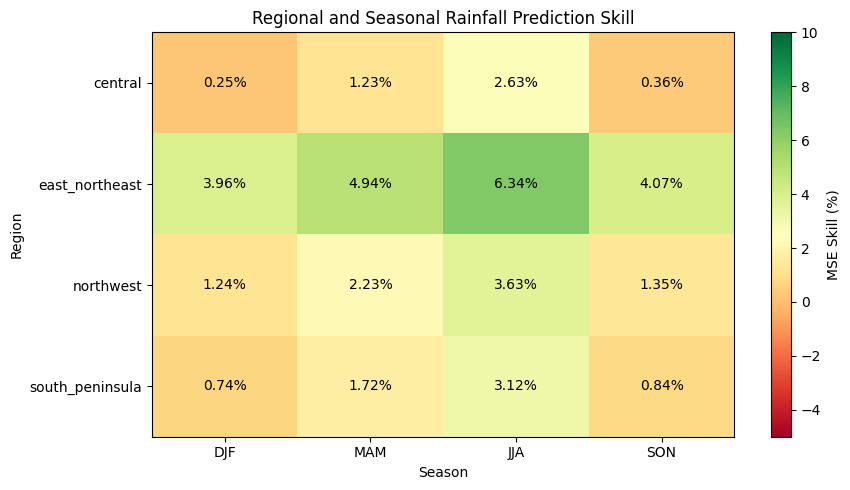

In [20]:
heatmap_data = grouped_metrics[
    (grouped_metrics["subset"] == "all") &
    (grouped_metrics["group_type"].isin(["region", "season"]))
]

region_order = [
    "central", "east_northeast", "northwest", "south_peninsula"
]
season_order = ["DJF", "MAM", "JJA", "SON"]

heatmap_values = []

for region in region_order:
    row = []
    for season in season_order:
        region_skill = heatmap_data.loc[
            (heatmap_data["group_type"] == "region") &
            (heatmap_data["group"] == region), "mse_skill"
        ].iloc[0]

        season_skill = heatmap_data.loc[
            (heatmap_data["group_type"] == "season") &
            (heatmap_data["group"] == season), "mse_skill"
        ].iloc[0]

        row.append((region_skill + season_skill) / 2)

    heatmap_values.append(row)

heatmap_df = pd.DataFrame(
    heatmap_values,
    index=region_order,
    columns=season_order
)

fig, ax = plt.subplots(figsize=(9, 5))

image = ax.imshow(
    heatmap_df.values * 100,
    aspect="auto",
    cmap="RdYlGn",
    vmin=-5,
    vmax=10
)

ax.set_xticks(range(len(season_order)), season_order)
ax.set_yticks(range(len(region_order)), region_order)
ax.set_title("Regional and Seasonal Rainfall Prediction Skill")
ax.set_xlabel("Season")
ax.set_ylabel("Region")

for i in range(len(region_order)):
    for j in range(len(season_order)):
        ax.text(
            j, i,
            f"{heatmap_df.iloc[i, j] * 100:.2f}%",
            ha="center", va="center"
        )

fig.colorbar(image, ax=ax, label="MSE Skill (%)")
fig.tight_layout()

fig.savefig(
    ARTIFACT_DIR / "01_regional_seasonal_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

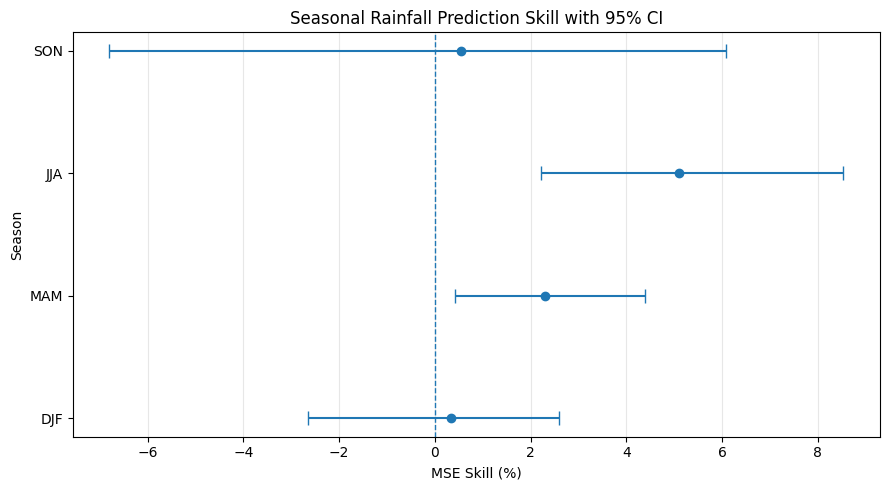

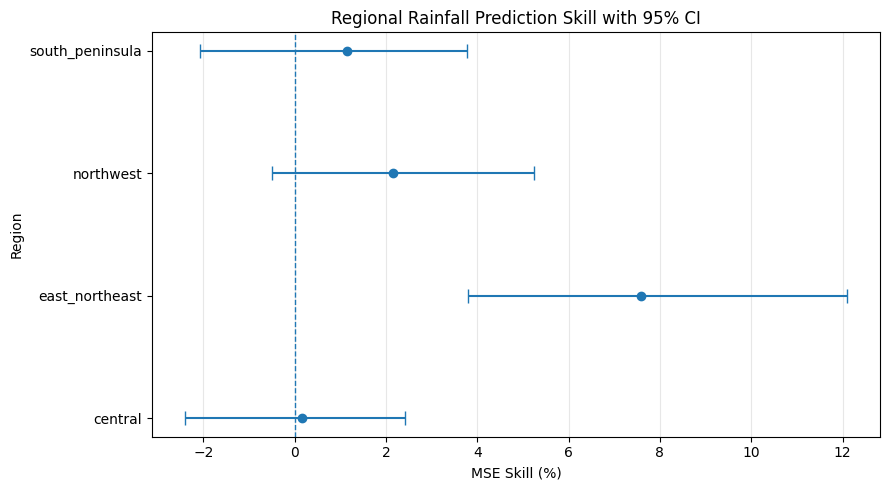

In [21]:
def plot_skill_ci(group_type, order, title, filename):
    point_data = grouped_metrics[
        (grouped_metrics["subset"] == "all") &
        (grouped_metrics["group_type"] == group_type)
    ].set_index("group")

    ci_data = group_skill_ci[
        (group_skill_ci["subset"] == "all") &
        (group_skill_ci["group_type"] == group_type)
    ].set_index("group")

    point_data = point_data.loc[order]
    ci_data = ci_data.loc[order]

    values = point_data["mse_skill"].values * 100
    lower = ci_data["lower_95"].values * 100
    upper = ci_data["upper_95"].values * 100

    errors = np.vstack([
        values - lower,
        upper - values
    ])

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.errorbar(
        values,
        order,
        xerr=errors,
        fmt="o",
        capsize=5
    )

    ax.axvline(0, linestyle="--", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("MSE Skill (%)")
    ax.set_ylabel(group_type.capitalize())
    ax.grid(axis="x", alpha=0.3)

    fig.tight_layout()
    fig.savefig(
        ARTIFACT_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


plot_skill_ci(
    "season",
    ["DJF", "MAM", "JJA", "SON"],
    "Seasonal Rainfall Prediction Skill with 95% CI",
    "02_seasonal_skill_ci.png"
)

plot_skill_ci(
    "region",
    ["central", "east_northeast", "northwest", "south_peninsula"],
    "Regional Rainfall Prediction Skill with 95% CI",
    "03_regional_skill_ci.png"
)

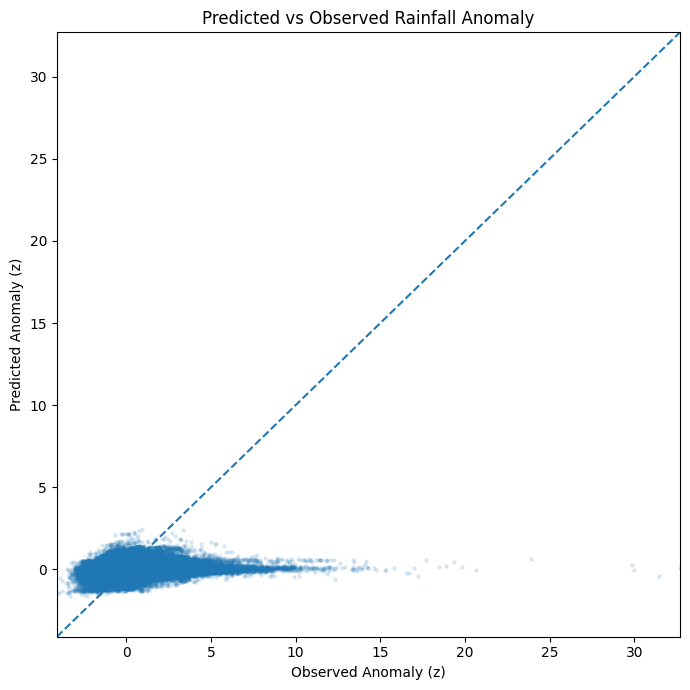

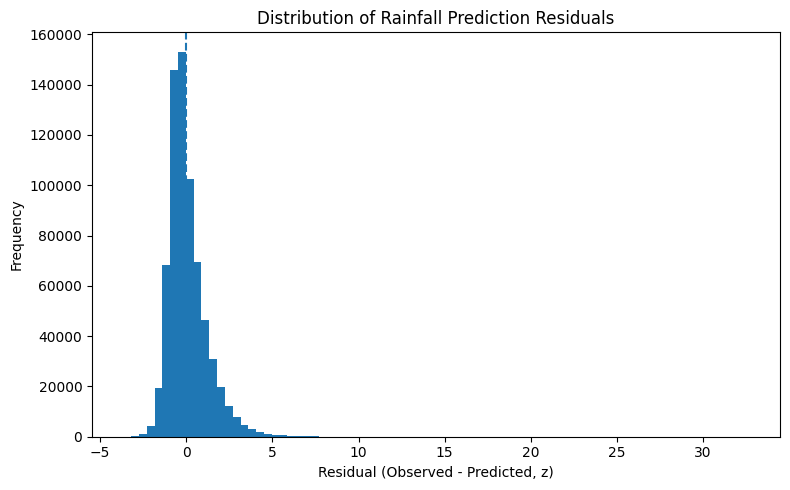

In [22]:
plot_data = test_df[["target_z"]].copy()
plot_data["pred_z"] = pred_lgbm
plot_data["residual"] = plot_data["target_z"] - plot_data["pred_z"]

fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(
    plot_data["target_z"],
    plot_data["pred_z"],
    alpha=0.12,
    s=5
)

limits = [
    min(plot_data["target_z"].min(), plot_data["pred_z"].min()),
    max(plot_data["target_z"].max(), plot_data["pred_z"].max())
]

ax.plot(limits, limits, linestyle="--")
ax.set_xlim(limits)
ax.set_ylim(limits)
ax.set_title("Predicted vs Observed Rainfall Anomaly")
ax.set_xlabel("Observed Anomaly (z)")
ax.set_ylabel("Predicted Anomaly (z)")

fig.tight_layout()
fig.savefig(
    ARTIFACT_DIR / "04_predicted_vs_observed.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    plot_data["residual"],
    bins=80
)

ax.axvline(0, linestyle="--")
ax.set_title("Distribution of Rainfall Prediction Residuals")
ax.set_xlabel("Residual (Observed - Predicted, z)")
ax.set_ylabel("Frequency")

fig.tight_layout()
fig.savefig(
    ARTIFACT_DIR / "05_residual_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

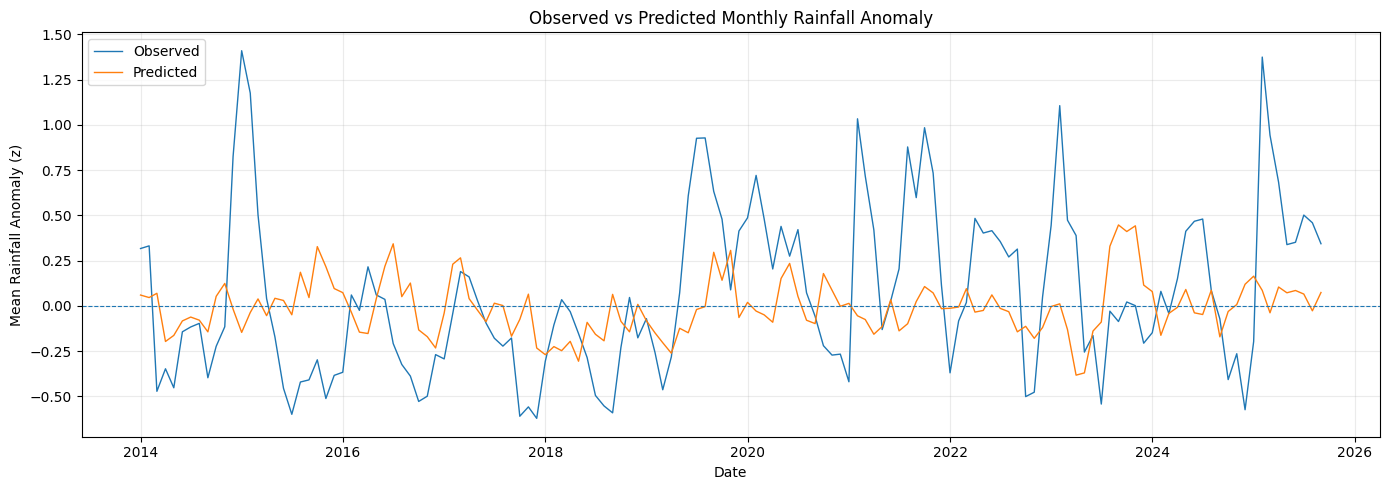

In [23]:
time_data = test_df[
    ["year", "month", "target_z"]
].copy()

time_data["pred_z"] = pred_lgbm

time_data = (
    time_data.groupby(["year", "month"])
    [["target_z", "pred_z"]]
    .mean()
    .reset_index()
)

time_data["date"] = pd.to_datetime(
    dict(
        year=time_data["year"],
        month=time_data["month"],
        day=1
    )
)

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    time_data["date"],
    time_data["target_z"],
    label="Observed",
    linewidth=1
)

ax.plot(
    time_data["date"],
    time_data["pred_z"],
    label="Predicted",
    linewidth=1
)

ax.axhline(0, linestyle="--", linewidth=0.8)
ax.set_title("Observed vs Predicted Monthly Rainfall Anomaly")
ax.set_xlabel("Date")
ax.set_ylabel("Mean Rainfall Anomaly (z)")
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(
    ARTIFACT_DIR / "06_observed_vs_predicted_timeseries.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

honest assessment: the model has learned a weak forecasting signal, but it is not yet a strong rainfall-anomaly predictor. It has some useful regional and seasonal skill, but it struggles to predict the magnitude of unusual rainfall events.

In [24]:
print("Overall point metrics:")
print(type(overall_point_metrics))
print(overall_point_metrics)

print("\nAvailable evaluation variables:")
for name in [
    "overall_bootstrap_ci",
    "bootstrap_ci_all",
    "bootstrap_ci_no_extremes",
    "overall_ci",
    "all_ci",
    "no_extremes_ci"
]:
    if name in globals():
        print(f"\n{name}:")
        print(globals()[name])

Overall point metrics:
<class 'pandas.core.frame.DataFrame'>
               rows       mse  mse_skill    rmse_z     mae_z    bias_z  \
subset                                                                   
all          693996  1.302454   0.021585  1.141251  0.822869 -0.073624   
no_extremes  692792  1.190837   0.021597  1.091255  0.810874 -0.060327   

                  acc        r2     rmse_mm      mae_mm   bias_mm  \
subset                                                              
all          0.162199  0.018581  189.998183  103.148540 -6.183088   
no_extremes  0.164798  0.019554  186.760760  102.426774 -5.292807   

             tercile_accuracy       hss  
subset                                   
all                  0.336453  0.016921  
no_extremes          0.336157  0.016284  

Available evaluation variables:


In [25]:
for name, value in globals().copy().items():
    if "boot" in name.lower() or "ci" in name.lower():
        if isinstance(value, (pd.DataFrame, pd.Series, dict)):
            print(
                name,
                type(value).__name__,
                getattr(value, "shape", "")
            )

persistence_coefficients dict 
tercile_thresholds DataFrame (59124, 4)
ci_all DataFrame (12, 2)
ci_no_extremes DataFrame (12, 2)
group_skill_ci DataFrame (16, 5)


In [27]:
print("Available parameter variables:")

for name, value in globals().copy().items():
    if "param" in name.lower() and isinstance(value, dict):
        print(f"\n{name}:")
        print(value)

print("\nLoaded model parameters:")
print(lgbm_model.params)

Available parameter variables:

DEFAULT_PARAMS:
{'n_estimators': 300, 'learning_rate': 0.05, 'num_leaves': 31, 'max_depth': -1, 'min_child_samples': 100, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 1.0, 'random_state': 42}

params_to_log:
{'n_estimators': 300, 'learning_rate': 0.05, 'num_leaves': 31, 'max_depth': -1, 'min_child_samples': 100, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 1.0, 'random_state': 42}

Loaded model parameters:
{'boosting': 'gbdt', 'objective': 'regression', 'metric': ['l2'], 'tree_learner': 'serial', 'device_type': 'cpu', 'data_sample_strategy': 'bagging', 'num_iterations': 300, 'learning_rate': 0.05, 'num_leaves': 31, 'num_threads': 10, 'seed': 42, 'deterministic': False, 'force_col_wise': False, 'force_row_wise': False, 'histogram_pool_size': -1, 'max_depth': -1, 'min_data_in_leaf': 100, 'min_sum_hessian_in_leaf': 0.001, 'bagging_fraction': 0.8, 'pos_bagging_fraction': 1, 'neg_bagging_fraction': 1, 'bagging_freq': 0, 'bagging_seed':

In [29]:
import subprocess
import hashlib
import numpy as np
import mlflow

from pathlib import Path

client = MlflowClient()

experiment = mlflow.set_experiment("final_model_test")

git_commit = subprocess.check_output(
    ["git", "rev-parse", "--short", "HEAD"],
    text=True
).strip()

dataset_md5 = hashlib.md5(
    Path(DATA_PATH).read_bytes()
).hexdigest()

metrics_to_log = {}

def add_numeric_metrics(destination, prefix, values):
    for name, value in values.items():
        if isinstance(value, (int, float, np.integer, np.floating)):
            if np.isfinite(value):
                destination[f"{prefix}_{name}"] = float(value)

# overall point metrics
for subset, row in overall_point_metrics.iterrows():
    add_numeric_metrics(metrics_to_log, subset, row)

# regional and seasonal point metrics
for _, row in grouped_metrics.iterrows():
    prefix = f"{row['subset']}_{row['group_type']}_{row['group']}"
    add_numeric_metrics(
        metrics_to_log,
        prefix,
        row.drop(labels=["subset", "group_type", "group"])
    )

# overall bootstrap confidence intervals
for subset, ci in [
    ("all", ci_all),
    ("no_extremes", ci_no_extremes)
]:
    for metric, row in ci.iterrows():
        metrics_to_log[f"{subset}_{metric}_lower_95"] = float(row["lower_95"])
        metrics_to_log[f"{subset}_{metric}_upper_95"] = float(row["upper_95"])

# regional and seasonal mse-skill confidence intervals
for _, row in group_skill_ci.iterrows():
    prefix = (
        f"{row['subset']}_{row['group_type']}_"
        f"{row['group']}_mse_skill"
    )
    metrics_to_log[f"{prefix}_lower_95"] = float(row["lower_95"])
    metrics_to_log[f"{prefix}_upper_95"] = float(row["upper_95"])

with mlflow.start_run(
    experiment_id=experiment.experiment_id,
    run_name="rain_v2_lgbm_final_test",
    log_system_metrics=False
) as run:

    mlflow.log_params(DEFAULT_PARAMS)

    mlflow.set_tags({
        "model": "LightGBM",
        "model_version": "4.7.0",
        "evaluation": "final_holdout_test",
        "split": "test",
        "test_period": "2014-2025",
        "dataset_version": "rain_v2_3month_dataset_02",
        "git_commit": git_commit,
        "dataset_md5": dataset_md5,
        "prediction_target": "three_month_rainfall_anomaly",
        "prediction_units": "standardized_anomaly_z",
        "confidence_interval": "95_percent_year_block_bootstrap",
        "system_metrics": "disabled"
    })

    mlflow.log_metrics(metrics_to_log)

    graph_files = [
    "01_regional_seasonal_heatmap.png",
    "02_seasonal_skill_ci.png",
    "03_regional_skill_ci.png",
    "04_predicted_vs_observed.png",
    "05_residual_distribution.png",
    "06_observed_vs_predicted_timeseries.png"
    ]

    for filename in graph_files:
        mlflow.log_artifact(
            str(artifact_dir / filename),
            artifact_path="graphs"
        )

    final_run_id = run.info.run_id

print("Final test run logged.")
print("Experiment:", experiment.name)
print("Run ID:", final_run_id)
print("Metrics logged:", len(metrics_to_log))
print("Git commit:", git_commit)
print("Dataset MD5:", dataset_md5)

🏃 View run rain_v2_lgbm_final_test at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/12/runs/1e5bb8f8dc77475594576d2b49a980ea
🧪 View experiment at: https://dagshub.com/Sharanya-0224/Climate-Change-Awareness-Dashboard.mlflow/#/experiments/12
Final test run logged.
Experiment: final_model_test
Run ID: 1e5bb8f8dc77475594576d2b49a980ea
Metrics logged: 314
Git commit: 28b6139
Dataset MD5: 8ea8f7473d958fb34548ab9e66dbff97


In [4]:
for name in [
    "test_df",
    "lgbm_model",
    "pred_lgbm",
    "overall_point_metrics",
    "grouped_metrics",
    "ci_all",
    "group_skill_ci"
]:
    print(name, ":", name in globals())

test_df : False
lgbm_model : False
pred_lgbm : False
overall_point_metrics : False
grouped_metrics : False
ci_all : False
group_skill_ci : False


In [3]:
from pathlib import Path
import numpy as np

save_dir = Path("../artifacts")
save_dir.mkdir(parents=True, exist_ok=True)

prediction_path = save_dir / "final_test_pred_lgbm.npy"

np.save(prediction_path, np.asarray(pred_lgbm))

print("Predictions saved:", prediction_path)
print("Prediction count:", len(pred_lgbm))
print("Prediction shape:", np.asarray(pred_lgbm).shape)

NameError: name 'pred_lgbm' is not defined

In [5]:
import sys, json, importlib
sys.path.insert(0, "../src")
import numpy as np, pandas as pd
import config
from evaluation import metrics as mt
from training import train_lgbm as tl

inputs = json.load(open(config.FEATURE_PATH))["inputs"]
cols = ["key", "year", "month", "region", "split", "target_z", "target_mm",
        "target_mean", "target_sd", "target_anom_mm"]
full = pd.read_parquet(config.DATA_PATH, columns=cols + inputs)
thr = mt.make_tercile_thresholds(full)                      # train rows only
test = full[full["split"] == "test"].reset_index(drop=True)
del full

# 1. predictions from model.txt, compared with the saved test predictions
booster = tl.load_booster(config.PACKAGE_DIR / "model.txt")
tl.check_feature_order(booster, inputs)
p = tl.predict_z(booster, test, inputs)
saved = np.load(config.PRECIP_DIR / "artifacts" / "final_test_pred_lgbm.npy")
print("test rows:", len(test), "| saved npy:", len(saved),
      "| max diff vs npy:", float(np.abs(p - saved).max()))
print("test years:", test["year"].min(), "-", test["year"].max(), "| n years:", test["year"].nunique())

# 2. overall, by region, by origin-month season, with year-block ranges
def row(name, part, pred):
    r = mt.evaluate_model(part, pred, thr, allow_test=True)
    ci = mt.bootstrap_ci(part, pred, thr, allow_test=True)
    return {"group": name, "n": r["all"]["n"],
            "skill": r["all"]["mse_skill"],
            "lower_95": ci.loc["mse_skill", "lower_95"], "upper_95": ci.loc["mse_skill", "upper_95"],
            "skill_no_ext": r["no_extremes"]["mse_skill"],
            "acc": r["all"]["acc"], "tercile_acc": r["all"]["tercile_accuracy"]}

rows = [row("overall", test, p)]
season = test["month"].map(mt.get_season)
for name, values in [("region", test["region"].astype(str)), ("season", season)]:
    for g in sorted(values.unique()):
        m = (values == g).values
        rows.append(row(f"{name}_{g}", test[m].reset_index(drop=True), p[m]))

res = pd.DataFrame(rows)
print(res.round(4).to_string(index=False))

# 3. save (new file, never overwrite)
out = config.PRECIP_DIR / "artifacts" / "test_results_lgbm.json"
assert not out.exists(), "file exists, pick a new name"
res.to_json(out, orient="records", indent=2)
print("saved:", out)

test rows: 693996 | saved npy: 693996 | max diff vs npy: 0.0
test years: 2014 - 2025 | n years: 12
                 group      n  skill  lower_95  upper_95  skill_no_ext    acc  tercile_acc
               overall 693996 0.0216    0.0035    0.0391        0.0216 0.1622       0.3365
        region_central 224325 0.0017   -0.0240    0.0242        0.0003 0.0958       0.3456
 region_east_northeast 115338 0.0759    0.0380    0.1210        0.0771 0.2257       0.3341
      region_northwest 230253 0.0216   -0.0050    0.0524        0.0213 0.1688       0.3403
region_south_peninsula 124080 0.0115   -0.0207    0.0378        0.0094 0.0924       0.3150
            season_DJF 172208 0.0033   -0.0266    0.0259        0.0031 0.1144       0.3446
            season_JJA 177214 0.0509    0.0221    0.0853        0.0508 0.2254       0.3366
            season_MAM 177293 0.0229    0.0042    0.0440        0.0246 0.2016       0.3272
            season_SON 167281 0.0054   -0.0680    0.0608       -0.0004 0.1855     